# Vorlesung Datenvisualisierung & Datastorytelling
## Räumliche Visualisierung – Übungsaufgabe

**Fallstudie:** Solarenergie in Bayern  
**Bearbeitungszeit:** ca. 90 Minuten  
**Werkzeuge:** Pandas, Plotnine, PopGrid und Plotly; GeoPandas ist vollständig vorgegeben

In dieser Übung geht es nicht um Geodatenaufbereitung, sondern um gute
**Visualisierungsentscheidungen**: passende Kennzahlen, verständliche
Farbcodierung, der Umgang mit Overplotting und eine ehrliche Interpretation.

> **Hinweis für Studierende:** Zellen mit dem Symbol 🔒 sind vorbereitet.
> Führe sie aus, ändere sie aber nicht. Bearbeite nur die mit **Aufgabe**
> gekennzeichneten Zellen und die Reflexionsfragen.

## Lernziele und Zeitplan

Nach der Übung kannst du …

- statische Karten mit GeoPandas und der Plotnine-Grammatik einordnen,
- land- und bevölkerungsgewichtete Blockkartogramme direkt vergleichen,
- Projektionsverzerrungen und den Nutzen von Gradnetz und Labels erklären,
- absolute und relative Kennzahlen in Choroplethen sinnvoll unterscheiden,
- kontinuierliche Farbskalen und klassierte Karten begründet einsetzen,
- Overplotting in Punktkarten erkennen,
- Punkte mit dem H3 Spatial Index in standardisierte Hexagonzellen aggregieren,
- Punkt-, H3- und geglättete Dichtekarten passend zur Fragestellung auswählen,
- Grenzen der Aussagekraft einer Stichprobe benennen,
- optional: einen selbst recherchierten OSM-Ort mit Folium beschriften.

### Arbeitsweise

- Führe Zellen mit **🔒 Vorgegeben** unverändert aus.
- Entferne in den Lösungszellen die Kommentarzeichen blockweise und ersetze nur `...`.
- Folge den nummerierten TODO-Schritten und nutze anschließend den Selbstcheck.
- Beantworte die Reflexion erst nach dem visuellen Vergleich der Karten.

### Überblick Aufgaben

| Phase | Inhalt | 
|---|---:|
| Vorbereitung | Daten laden und prüfen |  
| Aufgabe 1 | Statisch: GeoPandas und Plotnine |  
| Aufgabe 2 | Landfläche vs. Bevölkerung mit PopGrid | 
| Aufgabe 3 | Vier Projektionen, mit/ohne Grid | 
| Aufgabe 4 | Absolute vs. relative Choroplethen | 
| Aufgabe 5 | Kontinuierlich vs. klassiert | 
| Aufgabe 6 | Punktkarte | 
| Aufgabe 7 | Points → H3-Hexagons | 
| Aufgabe 8 | Geglättete Dichtekarte | 
| Aufgabe 9 | Synthese: PV-Leistung pro 1.000 Einwohner | 
| Aufgabe 10 | Folium: Koordinaten auf Basiskarte zeigen | 

## Daten und Aussagegrenzen

Wir verwenden ausschließlich lokale Dateien aus demselben Aufgabenordner:

- `landkreise_simplify20.geojson`: vereinfachte bayerische Landkreise,
- `gemeinden_simplify20.geojson`: vereinfachte bayerische Gemeinden,
- `desc_solar_de.csv`: **Stichprobe** mit 5.000 Solaranlagen aus Deutschland.

**Die Solardatei ist kein vollständiger Registerauszug.** Ergebnisse zu PV-Anlagen
beschreiben daher nur die vorliegende Stichprobe und dürfen nicht als vollständige
Bestandsaufnahme Bayerns interpretiert werden. Vereinfachte Grenzen können außerdem
dazu führen, dass einzelne Punkte keinem Polygon zugeordnet werden.

Wichtig: Die Daten sind lokal. Nur die Hintergrundkacheln der interaktiven Basiskarten
benötigen eine Internetverbindung.

### Zusatzpaket

Für Aufgabe 2 wird `popgrid==0.7.1` verwendet. Im Kurs-Kernel ist es installiert.
Falls der Import in einer anderen Umgebung fehlschlägt, führe einmalig
`%pip install popgrid==0.7.1` aus und starte anschließend den Kernel neu.



Für Aufgabe 7 wird zusätzlich `h3==4.5.1` verwendet. Falls das Paket in einer
anderen Umgebung fehlt, führe einmalig `%pip install h3==4.5.1` aus und starte
den Kernel neu.


In [64]:
# OPTIONAL: Paketumgebung für diese Übung installieren
#
# Diese Zelle ist vollständig auskommentiert und verändert beim normalen Ausführen
# nichts. Falls Pakete fehlen, entferne in der letzten Zeile das führende `#`, führe
# die Zelle genau einmal aus und starte anschließend den Notebook-Kernel neu.
# `%pip` installiert in genau die Python-Umgebung des aktuell gewählten Kernels.
#
# %pip install numpy==2.2.5 pandas==2.2.3 geopandas==1.1.1 matplotlib==3.10.5 plotly==5.22.0 folium==0.20.0 plotnine==0.12.4 popgrid==0.7.1 h3==4.5.1 ipykernel==6.29.5

In [65]:
# 🔒 Vorgegeben: Bibliotheken und gemeinsame Darstellungsoptionen
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import folium
from IPython.display import display
from plotnine import (
    ggplot,
    aes,
    geom_map,
    scale_fill_cmap,
    coord_equal,
    theme_void,
    theme,
    element_text,
    labs,
)

try:
    from popgrid import AreaGrid, PopGrid
except ModuleNotFoundError as error:
    raise ModuleNotFoundError(
        "Das Zusatzpaket 'popgrid' fehlt. Führe einmalig "
        "`%pip install popgrid==0.7.1` aus und starte den Kernel neu."
    ) from error


try:
    import h3
except ModuleNotFoundError as error:
    raise ModuleNotFoundError(
        "Das Zusatzpaket 'h3' fehlt. Führe einmalig "
        "`%pip install h3==4.5.1` aus und starte den Kernel neu."
    ) from error


pd.set_option("display.max_columns", 30)
warnings.filterwarnings("ignore", message="Geometry is in a geographic CRS")

BAVARIA_CENTER = {"lat": 48.95, "lon": 11.40}
BAVARIA_ZOOM = 5.8

print("Bibliotheken geladen.")

Bibliotheken geladen.


### 🔒 Portable Datenpfade

Die folgende Zelle ersetzt fest codierte absolute Pfade. Sie funktioniert sowohl,
wenn Jupyter im Aufgabenordner gestartet wurde, als auch beim Start im Repository-
Hauptordner. Die beiden GeoJSON-Referenzen zeigen damit zuverlässig auf die
mitgelieferten Dateien.

In [66]:
# 🔒 Vorgegeben: Ordner mit allen drei lokalen Datendateien finden
REQUIRED_FILES = {
    "landkreise_simplify20.geojson",
    "gemeinden_simplify20.geojson",
    "desc_solar_de.csv",
}

def find_data_dir() -> Path:
    cwd = Path.cwd().resolve()
    candidates = []
    for root in (cwd, *cwd.parents):
        candidates.extend(
            [root, root / "assignments" / "5_Räumliche_Visualisierung"]
        )

    for candidate in dict.fromkeys(candidates):
        if all((candidate / filename).is_file() for filename in REQUIRED_FILES):
            return candidate

    raise FileNotFoundError(
        "Datendateien nicht gefunden. Lege Notebook, CSV und beide GeoJSON-"
        "Dateien gemeinsam in assignments/5_Räumliche_Visualisierung ab."
    )

DATA_DIR = find_data_dir()
LANDKREISE_PATH = DATA_DIR / "landkreise_simplify20.geojson"
GEMEINDEN_PATH = DATA_DIR / "gemeinden_simplify20.geojson"
SOLAR_PATH = DATA_DIR / "desc_solar_de.csv"

print(f"Datenordner: {DATA_DIR}")

Datenordner: C:\Users\Matthias\code\th_nue_dataviz_2026\assignments\5_Räumliche_Visualisierung


### 🔒 Geodaten vorbereiten

Diese GeoPandas-Schritte sind **kein Übungsinhalt**. Die Zelle lädt die Polygone,
vereinheitlicht das Koordinatensystem, extrahiert Bevölkerungswerte und erzeugt das
GeoJSON-Objekt, das Plotly für den Schlüsselabgleich benötigt.

In [67]:
# 🔒 Vorgegeben: sämtliche GeoPandas-Funktionalität für Landkreis-Karten und Kartogramm
def parse_destatis(value):
    # Die verschachtelte destatis-Angabe robust als Dictionary lesen.
    if isinstance(value, dict):
        return value
    if isinstance(value, str):
        try:
            return json.loads(value)
        except json.JSONDecodeError:
            return {}
    return {}

landkreise = gpd.read_file(LANDKREISE_PATH).to_crs("EPSG:4326")
gemeinden = gpd.read_file(GEMEINDEN_PATH).to_crs("EPSG:4326")

landkreis_stats = landkreise["destatis"].map(parse_destatis)
landkreise["population"] = pd.to_numeric(
    landkreis_stats.map(lambda item: item.get("population")),
    errors="coerce",
)

# Flächen werden in einem metrischen CRS berechnet, nicht in Längen-/Breitengraden.
landkreise_metric = landkreise.to_crs("EPSG:25832")
landkreise["area_km2"] = landkreise_metric.geometry.area / 1_000_000
landkreise["population_density"] = (
    landkreise["population"] / landkreise["area_km2"]
)

landkreise["AGS_0"] = landkreise["AGS_0"].astype(str)
gemeinden["AGS_0"] = gemeinden["AGS_0"].astype(str)

# Sieben Regierungsbezirke für das kompakte PopGrid-Kartogramm bilden.
REGIERUNGSBEZIRK_NAMES = {
    "1": "Oberbayern",
    "2": "Niederbayern",
    "3": "Oberpfalz",
    "4": "Oberfranken",
    "5": "Mittelfranken",
    "6": "Unterfranken",
    "7": "Schwaben",
}
landkreise["regierungsbezirk"] = (
    landkreise["SN_R"].astype(str).map(REGIERUNGSBEZIRK_NAMES)
)
regierungsbezirke = (
    landkreise[["regierungsbezirk", "population", "geometry"]]
    .dissolve(
        by="regierungsbezirk",
        aggfunc={"population": "sum"},
    )
    .reset_index()
    .to_crs("EPSG:4326")
)

# Nur Join-Schlüssel und Geometrie halten das Plotly-GeoJSON klein.
landkreise_geojson = json.loads(
    landkreise[["AGS_0", "geometry"]].to_json()
)

In [68]:
# 🔒 Vorgegeben: Solardaten laden, auf Bayern filtern und kurz validieren
solar = pd.read_csv(SOLAR_PATH)
solar_bayern = (
    solar.loc[
        solar["state"].eq("Bayern")
        & solar["lat"].notna()
        & solar["lon"].notna()
        & solar["unit_net_capacity"].notna()
    ]
    .copy()
)

data_check = pd.DataFrame(
    {
        "Datensatz": [
            "Landkreise",
            "Regierungsbezirke",
            "Gemeinden",
            "Solaranlagen Bayern",
        ],
        "Beobachtungen": [
            len(landkreise),
            len(regierungsbezirke),
            len(gemeinden),
            len(solar_bayern),
        ],
    }
)

assert landkreise["population"].notna().all()
assert landkreise["population_density"].gt(0).all()
assert len(regierungsbezirke) == 7
assert len(solar_bayern) > 0

display(data_check)
display(
    landkreise[
        ["GEN", "population", "area_km2", "population_density"]
    ].head().round(1)
)

,Datensatz,Beobachtungen
0,Landkreise,96
1,Regierungsbezirke,7
2,Gemeinden,2235
3,Solaranlagen Bayern,1280


,GEN,population,area_km2,population_density
0,Ingolstadt,136981,133.6,1025.1
1,München,1471508,311.4,4725.2
2,Rosenheim,63324,36.8,1721.4
3,Altötting,111210,570.0,195.1
4,Berchtesgadener Land,105722,841.0,125.7


In [69]:
# 🔒 Vorgegeben: Hilfsmittel für eine echte, aber kompakt gespeicherte Klassierung
QUINTILE_LABELS = [
    "Q1 · sehr niedrig",
    "Q2 · niedrig",
    "Q3 · mittel",
    "Q4 · hoch",
    "Q5 · sehr hoch",
]

def stepped_colorscale(colors):
    # Aus fünf Farben eine stufige Plotly-Farbskala erzeugen.
    scale = []
    n_colors = len(colors)
    for index, color in enumerate(colors):
        scale.extend(
            [(index / n_colors, color), ((index + 1) / n_colors, color)]
        )
    return scale

## Teil A – Drei kurze Einstiegsaufgaben

Die nächsten Aufgaben führen drei Grundideen kompakt ein: statische Karten als
geschichtete Grafik, Flächenverzerrung im Kartogramm und projektionsabhängige
Weltbilder. Danach folgt die zusammenhängende Bayern-Fallstudie.

## Aufgabe 1 – Statische Karten mit GeoPandas und Plotnine (7 Min.)

Führe zuerst die vollständig vorgegebene GeoPandas-Karte aus. Erzeuge danach mit
Plotnine dieselbe Choroplethe für `population_density`.

Nutze `ggplot`, `aes(fill=...)`, `geom_map`, eine sequenzielle Viridis-Skala,
`coord_equal` und `theme_void`. Der inhaltliche Vergleich ist wichtiger als ein
pixelidentisches Layout.

**Erfolgskriterium:** Beide statischen Karten zeigen dieselbe Kennzahl, Einheit und
Farbrichtung; Achsen und unnötige Dekoration fehlen.

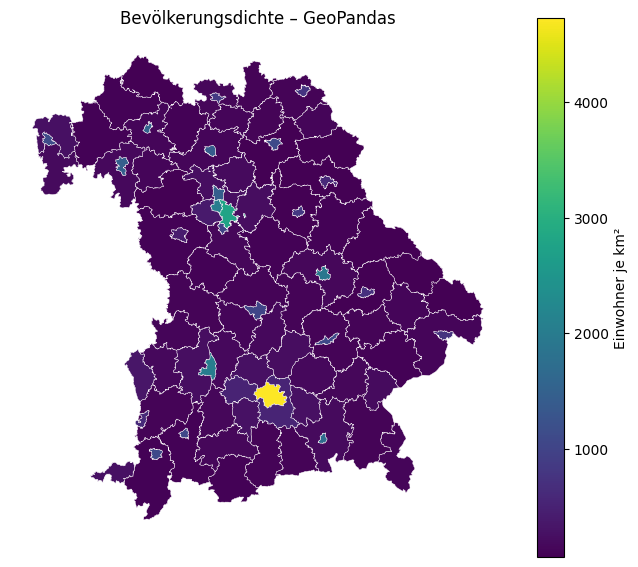

In [70]:
# 🔒 Vorgegeben: GeoPandas-Variante; keine Ergänzung erforderlich
fig_static, ax_static = plt.subplots(figsize=(8, 7))
landkreise.plot(
    column="population_density",
    cmap="viridis",
    legend=True,
    legend_kwds={"label": "Einwohner je km²"},
    edgecolor="white",
    linewidth=0.3,
    ax=ax_static,
)
ax_static.set_title("Bevölkerungsdichte – GeoPandas")
ax_static.set_axis_off()
plt.show()

In [71]:
# DEINE LÖSUNG ZU AUFGABE 1
# Lernfokus: dieselbe Kennzahl mit der Grammar of Graphics abbilden.
# Die GeoPandas-Referenzkarte in der Zelle darüber ist vollständig vorgegeben.

# TODO 1: Entferne die Kommentarzeichen im Block.
# TODO 2: Trage bei fill die Spalte "population_density" ein.
# TODO 3: Ergänze einen Titel, der Kennzahl und Darstellungsbibliothek nennt.

# static_plotnine = (
#     ggplot(landkreise, aes(fill=...))
#     + geom_map(color="white", size=0.2)
#     + scale_fill_cmap(
#         name="Einw. je km²",
#     )
#     + coord_equal()
#     + theme_void()
#     + labs(title=...)
#     + theme(plot_title=element_text(size=12, weight="bold"))
# )
# static_plotnine

# SELBSTCHECK: Karte und Legende zeigen Bevölkerungsdichte, nicht Bevölkerung.

**Reflexion (2 Sätze):** Welche Bestandteile der Karte erkennst du in beiden APIs
wieder? Welcher Programmierstil erscheint dir für wiederholbare Gestaltung klarer?

_Deine Antwort:_ …

## Aufgabe 2 – Landfläche und Bevölkerung mit PopGrid vergleichen (8 Min.)

Das [PopGrid-Beispiel](https://github.com/databites-tech/popgrid#your-own-data)
stellt dieselben Regionen mit denselben Farben nebeneinander dar, gewichtet sie aber
unterschiedlich:

- **Landfläche (`AreaGrid`)**: Die Zahl der Blöcke folgt der geografischen Fläche.
- **Bevölkerung (`PopGrid`)**: Die Zahl der Blöcke folgt der Einwohnerzahl.

Erzeuge beide Grids aus den sieben vorbereiteten bayerischen Regierungsbezirken mit
`n=1000` und `color_mode="layouts"`. Zeichne sie anschließend mit `.draw(...)` in
zwei Matplotlib-Achsen nebeneinander. Bei 1.000 Blöcken steht ein Block näherungsweise
für 0,1 % der jeweiligen Gesamtgröße.

**Erfolgskriterium:** Beide Karten stehen in einer Zeile, derselbe Regierungsbezirk
hat in beiden Karten dieselbe Farbe, alle sieben Bezirke sind beschriftet und die
Titel unterscheiden klar zwischen Landfläche und Bevölkerung.

In [72]:
# DEINE LÖSUNG ZU AUFGABE 2
# Lernfokus: dieselben Bezirke einmal nach Fläche und einmal nach Bevölkerung gewichten.
# Die Bildung der sieben Regierungsbezirke mit GeoPandas ist bereits abgeschlossen.

# Schritt 1: Gemeinsame Datengrundlage für beide Karten übernehmen.
# cartogram_data = regierungsbezirke[
#     ["regierungsbezirk", "population", "geometry"]
# ].copy()

# Schritt 2: Flächenraster erzeugen.
# TODO: region_col="regierungsbezirk" und n=1000 einsetzen.
# area_grid = AreaGrid.from_geodataframe(
#     cartogram_data,
#     region_col=...,
#     n=...,
#     color_mode="layouts",
# )

# Schritt 3: Bevölkerungsraster erzeugen.
# TODO: Dieselbe Regionsspalte, weight_col="population" und n=1000 einsetzen.
# population_grid = PopGrid.from_geodataframe(
#     cartogram_data,
#     region_col=...,
#     weight_col=...,
#     n=...,
#     color_mode="layouts",
# )

# Schritt 4: Zwei Achsen anlegen und jedes Grid auf die passende Achse zeichnen.
# fig_cartograms, (ax_area, ax_population) = plt.subplots(
#     1, 2, figsize=(16, 8)
# )
# draw_options = {
#     "background_style": "none",
#     "show_labels": True,
#     "label_min_cells": 3,
# }
# area_grid.draw(..., **draw_options)        # Verwende ax_area.
# population_grid.draw(..., **draw_options)  # Verwende ax_population.

# Schritt 5: Aussagekräftige Titel ergänzen.
# ax_area.set_title(..., fontsize=14, fontweight="bold")
# ax_population.set_title(..., fontsize=14, fontweight="bold")
# fig_cartograms.suptitle(
#     "Bayerns Regierungsbezirke: Fläche und Bevölkerung",
#     fontsize=17,
#     fontweight="bold",
# )
# fig_cartograms.tight_layout()
# fig_cartograms

# SELBSTCHECK: Ein Bezirk hat links und rechts dieselbe Farbe, aber oft verschieden
# viele Blöcke. Links steht die Blockzahl für Fläche, rechts für Bevölkerung.

**Reflexion (3–4 Sätze):** Welche Größe repräsentiert ein Block links und rechts?
Welche Regierungsbezirke gewinnen in der Bevölkerungskarte sichtbar Blöcke, welche
verlieren? Warum müssen Farben und Blockgröße in beiden Karten identisch bleiben?
Welche geografischen Details sind in Blockkarten nicht mehr exakt ablesbar?

_Deine Antwort:_ …

## Aufgabe 3 – Projektionen und Kartendekoration mit Plotly (12 Min.)

Verwende den Gapminder-Datensatz von Plotly für 2007 und visualisiere die
Lebenserwartung als Welt-Choroplethe. Vergleiche nacheinander:

- `mercator`,
- `natural earth`,
- `equirectangular`,
- `orthographic`.

Achte besonders auf die polnahen beziehungsweise großflächigen Gebiete
**Russland, Grönland und Antarktis**.

Erzeuge für **jede Projektion zwei Varianten**:

1. reduziert: ohne Titel, Legendenlabel, Ländergrenzen und Gradnetz,
2. orientierend: mit Titel, verständlichem Legendenlabel, Küsten- und
   Ländergrenzen sowie Breiten-/Längengrad-Grid.

Die Ländernamen bleiben als Hover-Information erhalten; „Labels“ bezeichnet hier
Titel und Legendenbeschriftung, nicht Text auf jedem Polygon.

> **Fußnote:** Für Russland, Grönland und die Antarktis liegen im verwendeten
> Gapminder-Datensatz 2007 keine Daten vor.

**Erfolgskriterium:** Acht Karten werden angezeigt.

In [73]:
# 🔒 Vorgegeben: No-Data-Gebiete für den Projektionsvergleich
gap_projection = px.data.gapminder().query("year == 2007").copy()

projection_no_data = pd.DataFrame(
    [
        {
            "country": "Russland",
            "iso_alpha": "RUS",
            "data_status": "Keine Daten im Gapminder-Datensatz 2007",
        },
        {
            "country": "Grönland",
            "iso_alpha": "GRL",
            "data_status": "Keine Daten im Gapminder-Datensatz 2007",
        },
        {
            "country": "Antarktis",
            "iso_alpha": "ATA",
            "data_status": "Keine Daten im Gapminder-Datensatz 2007",
        },
    ]
)

display(projection_no_data)

,country,iso_alpha,data_status
0,Russland,RUS,Keine Daten im Gapminder-Datensatz 2007
1,Grönland,GRL,Keine Daten im Gapminder-Datensatz 2007
2,Antarktis,ATA,Keine Daten im Gapminder-Datensatz 2007


In [74]:
# DEINE LÖSUNG ZU AUFGABE 3
# Lernfokus: Projektion und Kartendekoration gezielt voneinander trennen.
# gap_projection und projection_no_data sind vollständig vorgegeben.

PROJECTIONS = [
    "mercator",
    "natural earth",
    "equirectangular",
    "orthographic",
]

# Schritt 1: Basiskarte erstellen.
# TODO: Nutze iso_alpha für locations, lifeExp für color, country für hover_name
# und den Funktionsparameter projection für die Projektion.
# def life_expectancy_map(projection, decorated=False):
#     figure = px.choropleth(
#         gap_projection,
#         locations=...,
#         color=...,
#         hover_name=...,
#         projection=...,
#         color_continuous_scale="Viridis",
#         labels=(
#             {"lifeExp": "Lebenserwartung (Jahre)"}
#             if decorated
#             else None
#         ),
#     )

#     # Schritt 2 (vorgegeben): No-Data-Gebiete als eigene graue Ebene ergänzen.
#     figure.add_trace(
#         go.Choropleth(
#             locations=projection_no_data["iso_alpha"],
#             locationmode="ISO-3",
#             z=[1] * len(projection_no_data),
#             zmin=0,
#             zmax=1,
#             colorscale=[[0, "#BDBDBD"], [1, "#BDBDBD"]],
#             showscale=False,
#             text=projection_no_data["country"],
#             customdata=projection_no_data["data_status"],
#             hovertemplate=(
#                 "<b>%{text}</b><br>%{customdata}<extra>No Data</extra>"
#             ),
#             marker_line_color="white",
#             marker_line_width=0.5,
#             name="No Data",
#         )
#     )

#     # Schritt 3: In der dekorierten Variante Orientierungshilfen einschalten.
#     # TODO: Ersetze die vier ... durch True und ergänze den Titel.
#     if decorated:
#         figure.update_layout(
#             title_text=...,
#             geo=dict(
#                 showframe=False,
#                 showcoastlines=...,
#                 projection_type=projection,
#                 showland=True,
#                 landcolor="#F2F2F2",
#                 showcountries=...,
#                 countrycolor="LightGray",
#                 lataxis_showgrid=...,
#                 lonaxis_showgrid=...,
#             ),
#             annotations=[
#                 dict(
#                     text=NO_DATA_FOOTNOTE,
#                     x=0,
#                     y=-0.08,
#                     xref="paper",
#                     yref="paper",
#                     xanchor="left",
#                     showarrow=False,
#                     font={"size": 10, "color": "#555555"},
#                 )
#             ],
#         )
#     else:
#         # Reduzierte Vergleichsvariante ohne Grenzen, Gradnetz und Legende.
#         figure.update_layout(
#             title=None,
#             coloraxis_showscale=False,
#             geo=dict(
#                 showframe=False,
#                 showcoastlines=False,
#                 projection_type=projection,
#                 showland=True,
#                 landcolor="#F2F2F2",
#                 showcountries=False,
#                 lataxis_showgrid=False,
#                 lonaxis_showgrid=False,
#             ),
#         )

#     figure.update_layout(
#         margin={
#             "l": 0,
#             "r": 0,
#             "t": 55 if decorated else 10,
#             "b": 55 if decorated else 0,
#         }
#     )
#     return figure

# Schritt 4: Jede Projektion einmal reduziert und einmal dekoriert anzeigen.
# for projection in PROJECTIONS:
#     print(f"{projection}: ohne Labels und Grid")
#     life_expectancy_map(projection, decorated=False).show()
#     print(f"{projection}: mit Labels und Grid")
#     life_expectancy_map(projection, decorated=True).show()

# SELBSTCHECK: Es erscheinen 4 × 2 Karten. Russland, Grönland und Antarktis sind
# grau und tragen keine erfundenen Werte.

**Reflexion (3–4 Sätze):** Vergleiche besonders Russland, Grönland und die Antarktis in
Mercator, Natural Earth, Equirectangular und Orthographic. Welche Größen- und
Formverzerrungen erkennst du? Was gewinnen und verlieren die Varianten durch
Labels, Grenzen und Gradnetz?

_Deine Antwort:_ …

## Teil B – Fallstudie Solarenergie in Bayern

Die folgenden Aufgaben wenden die Visualisierungsentscheidungen auf Landkreise,
Anlagenpunkte und Gemeinden an. Drei Darstellungen derselben Punktdaten – einzelne
Marker, H3-Hexagons und geglättete Dichte – machen die Folgen räumlicher Aggregation
direkt vergleichbar.

## Aufgabe 4 – Absolute oder relative Werte? (8 Min.)

Eine Choroplethe färbt Flächen anhand einer Kennzahl. Erstelle zwei Karten der
bayerischen Landkreise:

1. absolute Bevölkerung (`population`),
2. Bevölkerungsdichte (`population_density`, Einwohner pro km²).

Nutze `px.choropleth`, verknüpfe DataFrame und GeoJSON über `AGS_0` und verwende
für beide Karten eine sequenzielle, farbenblindheitsfreundliche Palette. Jeder
Tooltip soll mindestens Landkreis, Bevölkerung, Fläche und Dichte zeigen.

**Erfolgskriterium:** Alle 96 Landkreise sind sichtbar; Titel, Legende und Einheiten
nennen eindeutig die dargestellte Kennzahl.

In [75]:
# DEINE LÖSUNG ZU AUFGABE 4
# Lernfokus: absolute Bevölkerung und relative Bevölkerungsdichte vergleichen.
# GeoPandas-Aufbereitung, GeoJSON und Join-Schlüssel sind bereits vorgegeben.

# Schritt 1: Eine wiederverwendbare Plotly-Funktion vervollständigen.
# TODO: Verwende die Funktionsparameter metric, palette und title an den markierten Stellen.
# def county_choropleth(metric, title, colorbar_title, palette):
#     fig = px.choropleth(
#         data_frame=landkreise,
#         geojson=landkreise_geojson,
#         locations="AGS_0",
#         featureidkey="properties.AGS_0",
#         color=...,
#         hover_name="GEN",
#         hover_data={
#             "population": ":,.0f",
#             "area_km2": ":.0f",
#             "population_density": ":.0f",
#             "AGS_0": False,
#         },
#         color_continuous_scale=...,
#         labels={
#             "population": "Einwohner",
#             "area_km2": "Fläche (km²)",
#             "population_density": "Einwohner je km²",
#         },
#         title=...,
#     )
#     fig.update_geos(fitbounds="locations", visible=False)
#     fig.update_layout(
#         margin={"l": 0, "r": 0, "t": 55, "b": 0},
#         coloraxis_colorbar={"title": colorbar_title},
#     )
#     return fig

# Schritt 2: Funktion einmal für population und einmal für population_density aufrufen.
# TODO: Ergänze metric, Titel, Legendentitel und eine sequenzielle Palette.
# fig_population = county_choropleth(
#     metric=...,
#     title=...,
#     colorbar_title=...,
#     palette=...,
# )
# fig_density = county_choropleth(
#     metric=...,
#     title=...,
#     colorbar_title=...,
#     palette=...,
# )
# fig_population.show()
# fig_density.show()

# SELBSTCHECK: Beide Karten zeigen dieselben 96 Landkreise, aber unterschiedliche
# räumliche Muster und eindeutig beschriftete Einheiten.

**Reflexion (2–3 Sätze):** Welche räumlichen Muster ändern sich zwischen den
beiden Karten? Für welche Fragestellung ist jeweils die absolute bzw. relative
Kennzahl passender?

_Deine Antwort:_ …

## Aufgabe 5 – Kontinuierlich oder klassiert? (7 Min.)

Die Dichtekarte aus Aufgabe 4 zeigt genaue Abstufungen. Für einen schnellen
Rangvergleich können Klassen geeigneter sein. Teile `population_density` mit
`pd.qcut` in fünf gleich große Gruppen (Quintile) und erstelle eine klassierte Karte.

Verwende die vorgegebene Funktion `stepped_colorscale`, den Wertebereich
`(0.5, 5.5)` und die Beschriftungen aus `QUINTILE_LABELS`. So entstehen fünf klar
getrennte Farben, ohne das GeoJSON für jede Klasse mehrfach im Notebook abzulegen.

**Erfolgskriterium:** Die Legende zeigt Q1 bis Q5 in sinnvoller Reihenfolge.

In [76]:
# DEINE LÖSUNG ZU AUFGABE 5
# Lernfokus: eine kontinuierliche Kennzahl in fünf gleich häufige Klassen überführen.

# Schritt 1: Dichtewerte mit qcut in Quintile 1 bis 5 einteilen.
# TODO: Verwende population_density und q=5.
# landkreise["density_quintile"] = (
#     pd.qcut(..., q=..., labels=False) + 1
# )

# Schritt 2: Die neue Klassenvariable kartieren. Die GeoJSON-Verknüpfung ist vorgegeben.
# TODO: Verwende density_quintile als color.
# fig_density_classes = px.choropleth(
#     data_frame=landkreise,
#     geojson=landkreise_geojson,
#     locations="AGS_0",
#     featureidkey="properties.AGS_0",
#     color=...,
#     range_color=(0.5, 5.5),
#     color_continuous_scale=stepped_colorscale(
#         px.colors.sequential.YlOrRd[2:7]
#     ),
#     hover_name="GEN",
#     hover_data={
#         "population_density": ":.0f",
#         "density_quintile": False,
#         "AGS_0": False,
#     },
#     labels={"population_density": "Einwohner je km²"},
#     title="Bevölkerungsdichte der Landkreise – Quintile",
# )
# fig_density_classes.update_geos(fitbounds="locations", visible=False)
# fig_density_classes.update_coloraxes(
#     colorbar={
#         "title": "Dichteklasse",
#         "tickvals": [1, 2, 3, 4, 5],
#         "ticktext": QUINTILE_LABELS,
#     }
# )
# fig_density_classes.update_layout(
#     margin={"l": 0, "r": 0, "t": 55, "b": 0}
# )
# fig_density_classes.show()

# SELBSTCHECK: Die Legende enthält genau Q1 bis Q5; Q1 steht für niedrige, Q5 für
# hohe Bevölkerungsdichte.

**Reflexion (2–3 Sätze):** Was wird mit Quintilen leichter erkennbar? Welche
Information geht gegenüber der kontinuierlichen Karte verloren?

_Deine Antwort:_ …

## Aufgabe 6 – Punktkarte und Overplotting (8 Min.)

Erstelle mit `px.scatter_mapbox` eine Punktkarte der bayerischen Solaranlagen.

- Position: `lat` und `lon`
- Farbe: `unit_net_capacity` (kW)
- Größe: Quadratwurzel der Nettoleistung, damit einzelne Ausreißer nicht alle
  anderen Marker unsichtbar machen
- Transparenz: etwa 0,55
- Tooltip: Ort, Anlagennummer und Nettoleistung

Verwende `mapbox_style="open-street-map"`, `BAVARIA_CENTER` und `BAVARIA_ZOOM`.

**Erfolgskriterium:** Die Karte zeigt einzelne Anlagen und bleibt trotz 1.280 Punkten
bedienbar. Die Legende nennt die Einheit kW.

In [77]:
# DEINE LÖSUNG ZU AUFGABE 6
# Lernfokus: Position, Farbe, Punktfläche und Transparenz sinnvoll kombinieren.

# Schritt 1: Quadratwurzel der Nettoleistung als gedämpfte Größenvariable berechnen.
# TODO: Verwende unit_net_capacity und begrenze negative Werte mit clip(lower=0).
# solar_bayern["marker_size"] = np.sqrt(
#     solar_bayern[...].clip(lower=0)
# )

# Schritt 2: Punktkarte erstellen.
# TODO: lat/lon für die Position, marker_size für size und unit_net_capacity für color.
# fig_points = px.scatter_mapbox(
#     solar_bayern,
#     lat=...,
#     lon=...,
#     size=...,
#     color=...,
#     size_max=18,
#     opacity=0.55,
#     hover_name="locality",
#     hover_data={
#         "unit_number": True,
#         "unit_net_capacity": ":.1f",
#         "marker_size": False,
#         "lat": False,
#         "lon": False,
#     },
#     color_continuous_scale="Viridis",
#     labels={
#         "unit_number": "Anlagennummer",
#         "unit_net_capacity": "Nettoleistung (kW)",
#     },
#     title="Solaranlagen in Bayern – Punktdarstellung (Stichprobe)",
#     center=BAVARIA_CENTER,
#     zoom=BAVARIA_ZOOM,
# )
# fig_points.update_layout(
#     mapbox_style="open-street-map",
#     margin={"l": 0, "r": 0, "t": 55, "b": 0},
# )
# fig_points.show()

# SELBSTCHECK: Hover zeigt Ort, Nummer und kW. Große Anlagen sind sichtbar, kleine
# Marker bleiben durch Quadratwurzel und Transparenz dennoch erkennbar.

**Reflexion (2–3 Sätze):** Wo tritt Overplotting auf? Welche Information kann
die Punktkarte gut vermitteln und welche nicht? Warum wird die Markergröße
transformiert?

_Deine Antwort:_ …

## Aufgabe 7 – Punkte mit dem H3 Spatial Index zu Hexagons aggregieren (12 Min.)

Die Punktkarte zeigt einzelne Anlagen, leidet aber in dichten Bereichen unter
Overplotting. Überführe deshalb jeden Anlagenstandort mit Ubers **H3 Spatial Index**
in eine standardisierte Hexagonzelle.

1. Verwende `h3.latlng_to_cell(lat, lon, H3_RESOLUTION)` mit Auflösung 5.
2. Aggregiere je `h3_cell` die Anlagenzahl und die summierte Nettoleistung.
3. Erzeuge mit der vorgegebenen Hilfsfunktion ein GeoJSON der belegten Zellen.
4. Visualisiere die Anlagenzahl mit `px.choropleth_mapbox`.

H3-Auflösung 5 entspricht global im Mittel rund 253 km² pro Hexagon. Die Zellen
sind hierarchisch adressierbar; tatsächliche Flächen variieren auf der Kugel leicht.

**Erfolgskriterium:** Die Summe von `installations` entspricht der Zahl der
bayerischen Anlagenpunkte und jede belegte H3-Zelle erscheint genau einmal.

In [78]:
# 🔒 Vorgegeben: H3-Zellgrenzen in ein Plotly-kompatibles GeoJSON umwandeln
def h3_cells_to_geojson(cell_ids):
    features = []
    for cell_id in cell_ids:
        # h3 liefert (lat, lon); GeoJSON erwartet [lon, lat].
        boundary = h3.cell_to_boundary(cell_id)
        ring = [[lon, lat] for lat, lon in boundary]
        ring.append(ring[0])
        features.append(
            {
                "type": "Feature",
                "properties": {"h3_cell": cell_id},
                "geometry": {
                    "type": "Polygon",
                    "coordinates": [ring],
                },
            }
        )
    return {"type": "FeatureCollection", "features": features}

In [79]:
# DEINE LÖSUNG ZU AUFGABE 7
# Lernfokus: viele Einzelpunkte über einen standardisierten räumlichen Index bündeln.
# Die Funktion h3_cells_to_geojson(...) ist vollständig vorgegeben.

H3_RESOLUTION = 5
solar_h3 = solar_bayern.copy()

# Schritt 1: Jeden Punkt einer H3-Zelle zuordnen.
# TODO: h3.latlng_to_cell erwartet zuerst lat, dann lon.
# solar_h3["h3_cell"] = [
#     h3.latlng_to_cell(..., ..., H3_RESOLUTION)
#     for lat, lon in zip(solar_h3["lat"], solar_h3["lon"])
# ]

# Schritt 2: Je Zelle Anlagen zählen und Nettoleistung summieren.
# TODO: Für installations die Funktion "size" verwenden; für net_capacity_kw
# die Spalte unit_net_capacity mit "sum" aggregieren.
# h3_summary = (
#     solar_h3.groupby("h3_cell", as_index=False)
#     .agg(
#         installations=("unit_number", ...),
#         net_capacity_kw=(..., "sum"),
#     )
# )

# Schritt 3 (vorgegeben): Zellgrenzen erzeugen und Vollständigkeit prüfen.
# h3_geojson = h3_cells_to_geojson(h3_summary["h3_cell"])
# assert h3_summary["installations"].sum() == len(solar_h3)
# assert len(h3_geojson["features"]) == len(h3_summary)

# Schritt 4: Anlagenzahl je Hexagon kartieren. Die GeoJSON-Schlüssel sind vorgegeben.
# fig_h3 = px.choropleth_mapbox(
#     h3_summary,
#     geojson=h3_geojson,
#     locations="h3_cell",
#     featureidkey="properties.h3_cell",
#     color="installations",
#     hover_data={
#         "h3_cell": True,
#         "installations": True,
#         "net_capacity_kw": ":.1f",
#     },
#     labels={
#         "installations": "Anlagen je H3-Zelle",
#         "net_capacity_kw": "Nettoleistung (kW)",
#     },
#     color_continuous_scale="Viridis",
#     title="Solaranlagen je H3-Zelle – Auflösung 5 (Stichprobe)",
#     center=BAVARIA_CENTER,
#     zoom=BAVARIA_ZOOM,
#     mapbox_style="open-street-map",
#     opacity=0.72,
# )
# fig_h3.update_layout(
#     margin={"l": 0, "r": 0, "t": 55, "b": 0}
# )
# fig_h3.show()

# SELBSTCHECK: Beide assert-Zeilen laufen ohne Fehler; jedes Hexagon erscheint nur
# einmal und die Summe der Anlagen bleibt unverändert.

**Reflexion (2–3 Sätze):** Was wird gegenüber der Punktkarte besser erkennbar? Wie würde
eine höhere H3-Auflösung die Karte verändern? Warum können Anlagenzahl und summierte
Nettoleistung zu unterschiedlichen Hotspots führen?

_Deine Antwort:_ …

## Aufgabe 8 – Dichtekarte statt Punktwolke (8 Min.)

Erstelle mit `px.density_mapbox` eine gewichtete Dichtekarte. Verwende
`unit_net_capacity` als Gewicht (`z`) und starte mit `radius=22`.

Eine Dichtekarte glättet benachbarte Beobachtungen. Sie zeigt Hotspots besser als
eine überlagerte Punktwolke, aber keine exakten Anlagenpositionen.

**Erfolgskriterium:** Titel und Legende machen deutlich, dass die Karte räumlich
geglättete **Nettoleistung** und nicht nur die Anzahl der Anlagen zeigt.

In [80]:
# DEINE LÖSUNG ZU AUFGABE 8
# Lernfokus: Hotspots durch räumliche Glättung statt einzelner Marker zeigen.

# TODO 1: Verwende lat und lon für die Position.
# TODO 2: Nutze unit_net_capacity als Gewicht z und starte mit radius=22.
# fig_density_map = px.density_mapbox(
#     solar_bayern,
#     lat=...,
#     lon=...,
#     z=...,
#     radius=...,
#     center=BAVARIA_CENTER,
#     zoom=BAVARIA_ZOOM,
#     mapbox_style="open-street-map",
#     color_continuous_scale="Inferno",
#     labels={
#         "unit_net_capacity": "geglättete Nettoleistung (kW)"
#     },
#     title="Räumliche Dichte der PV-Nettoleistung (Stichprobe)",
# )
# fig_density_map.update_layout(
#     margin={"l": 0, "r": 0, "t": 55, "b": 0}
# )
# fig_density_map.show()

# SELBSTCHECK: Die Karte zeigt geglättete Leistung, nicht exakte Anlagenpositionen.
# Teste optional einen kleineren/größeren radius und beschreibe die Veränderung.

**Reflexion (2–3 Sätze):** Welche Muster sind gegenüber der Punktkarte leichter
zu sehen? Wie verändert der Radius die Aussage? Welche Detailinformation geht
verloren?

_Deine Antwort:_ …

## 🔒 Vorbereitung für Aufgabe 9: räumliche Zuordnung

Die folgende Zelle erledigt den Point-in-Polygon-Join vollständig mit GeoPandas:
Anlagenpunkte werden Gemeinden zugeordnet und anschließend je Gemeinde aggregiert.
Diese technische Geodatenoperation ist **vorgegeben und nicht zu bearbeiten**.

Gemeinden ohne Anlage in der Stichprobe werden für die Karte nicht als „null“
interpretiert, sondern ausgelassen. Das verhindert die falsche Aussage, dort gebe es
nachweislich keine Anlagen.

In [81]:
# 🔒 Vorgegeben: sämtliche GeoPandas-Funktionalität für Aufgabe 9
gemeinde_stats = gemeinden["destatis"].map(parse_destatis)
gemeinden["population"] = pd.to_numeric(
    gemeinde_stats.map(lambda item: item.get("population")),
    errors="coerce",
)

solar_points = gpd.GeoDataFrame(
    solar_bayern.copy(),
    geometry=gpd.points_from_xy(
        solar_bayern["lon"], solar_bayern["lat"]
    ),
    crs="EPSG:4326",
)

solar_with_municipality = gpd.sjoin(
    solar_points,
    gemeinden[["AGS_0", "GEN", "population", "geometry"]],
    how="inner",
    predicate="within",
)

capacity_by_municipality = (
    solar_with_municipality.groupby(
        ["AGS_0", "GEN", "population"], as_index=False
    )
    .agg(
        installations=("unit_number", "size"),
        net_capacity_kw=("unit_net_capacity", "sum"),
    )
)

# Für Plotly nur Gemeinden mit Beobachtungen und nur die nötigen Felder exportieren.
municipalities_observed = gemeinden.loc[
    gemeinden["AGS_0"].isin(capacity_by_municipality["AGS_0"]),
    ["AGS_0", "geometry"],
].copy()
gemeinden_capacity_geojson = json.loads(
    municipalities_observed.to_json()
)

print(
    f"Zugeordnet: {len(solar_with_municipality):,} von "
    f"{len(solar_bayern):,} Anlagen; "
    f"Gemeinden mit Beobachtung: {len(capacity_by_municipality):,}."
)
display(capacity_by_municipality.head())

Zugeordnet: 1,278 von 1,280 Anlagen; Gemeinden mit Beobachtung: 792.


,AGS_0,GEN,population,installations,net_capacity_kw
0,09161000,Ingolstadt,136981.0,3,450.75
1,09162000,München,1471508.0,7,418.38
2,09163000,Rosenheim,63324.0,5,468.28
3,09171112,Burghausen,18701.0,3,223.32
4,09171113,Burgkirchen a.d. Alz,10460.0,1,220.00


## Aufgabe 9 – PV-Leistung je 1.000 Einwohner (12 Min.)

Erzeuge eine faire Vergleichskennzahl und eine abschließende Gemeindekarte:

1. Berechne `pv_kw_per_1000` = Nettoleistung in kW / Bevölkerung × 1.000.
2. Teile die Kennzahl mit `pd.qcut` in fünf Quintile (`pv_quintile`).
3. Erstelle eine `px.choropleth_mapbox`-Karte mit dem vorgegebenen
   `gemeinden_capacity_geojson`.
4. Zeige im Tooltip Gemeinde, Zahl der Anlagen, gesamte Nettoleistung,
   Bevölkerung und die normierte Kennzahl.

Verwende wieder eine stufige Farbskala, `range_color=(0.5, 5.5)`, eine Deckkraft
um 0,75 sowie die bekannte Bayern-Zentrierung.

**Erfolgskriterium:** Die Karte nennt im Titel sichtbar „Stichprobe“ und in der
Legende die Bezugsgröße „je 1.000 Einwohner“.

In [82]:
# DEINE LÖSUNG ZU AUFGABE 9
# Lernfokus: eine absolute Leistung auf Bevölkerung beziehen und fair vergleichen.
# Räumliche Zuordnung und GeoJSON wurden in der vorgegebenen Zelle vorbereitet.

# Schritt 1: kW je 1.000 Einwohner berechnen.
# TODO: Zähler net_capacity_kw, Nenner population, anschließend mit 1_000 multiplizieren.
# capacity_by_municipality["pv_kw_per_1000"] = (
#     capacity_by_municipality[...]
#     / capacity_by_municipality[...]
#     * 1_000
# )

# Schritt 2: Kennzahl in fünf Quintile einteilen.
# TODO: Verwende pv_kw_per_1000 und q=5.
# capacity_by_municipality["pv_quintile"] = (
#     pd.qcut(..., q=..., labels=False) + 1
# )

# Schritt 3: Quintile kartieren. GeoJSON-Verknüpfung und Tooltip sind vorgegeben.
# TODO: Verwende pv_quintile als color.
# fig_capacity = px.choropleth_mapbox(
#     capacity_by_municipality,
#     geojson=gemeinden_capacity_geojson,
#     locations="AGS_0",
#     featureidkey="properties.AGS_0",
#     color=...,
#     range_color=(0.5, 5.5),
#     color_continuous_scale=stepped_colorscale(
#         px.colors.sequential.Plasma[2:7]
#     ),
#     hover_name="GEN",
#     hover_data={
#         "installations": True,
#         "net_capacity_kw": ":.1f",
#         "population": ":,.0f",
#         "pv_kw_per_1000": ":.1f",
#         "pv_quintile": False,
#         "AGS_0": False,
#     },
#     labels={
#         "installations": "Anlagen in der Stichprobe",
#         "net_capacity_kw": "Nettoleistung (kW)",
#         "population": "Einwohner",
#         "pv_kw_per_1000": "kW je 1.000 Einwohner",
#     },
#     title=(
#         "PV-Nettoleistung je 1.000 Einwohner – Gemeinden "
#         "(Stichprobe)"
#     ),
#     center=BAVARIA_CENTER,
#     zoom=BAVARIA_ZOOM,
#     mapbox_style="open-street-map",
#     opacity=0.75,
# )
# fig_capacity.update_coloraxes(
#     colorbar={
#         "title": "Quintil",
#         "tickvals": [1, 2, 3, 4, 5],
#         "ticktext": QUINTILE_LABELS,
#     }
# )
# fig_capacity.update_layout(
#     margin={"l": 0, "r": 0, "t": 55, "b": 0}
# )
# fig_capacity.show()

# SELBSTCHECK: Titel enthält „Stichprobe“, Hover zeigt kW je 1.000 Einwohner und
# die fünf Quintile erscheinen in der richtigen Reihenfolge.

**Reflexion (3–4 Sätze):** Warum ist „pro 1.000 Einwohner“ nicht dasselbe wie
gesamte Leistung? Welche Rolle spielt ein kleiner Nenner? Welche Aussagen sind
wegen der Stichprobe ausdrücklich nicht zulässig?

_Deine Antwort:_ …

## Teil C – Folium (je ca. 10 Min.)

Die Aufgaben verbinden selbst recherchierte Koordinaten und vorhandene Daten
mit interaktiven Markern. 

### C1 – Einen selbst gewählten OSM-Ort markieren

1. Öffne [OpenStreetMap](https://www.openstreetmap.org/) und suche einen Ort, zum
   Beispiel die TH Nürnberg, einen Park, ein Café oder deinen Lieblingsclub.
2. Wähle den Punkt möglichst genau aus. Die Geokoordinaten (Lat/Long) kannst Du ablesen Über
 - **Rechtsklick auf den Punkt und Adresse anzeigen** - Es öffnet sich im Browser links ein Zusatzfenster mit der Koordinate 
 - **Teilen** 
 - **URL-Teil** `#map=Zoom/Breitengrad/Längengrad` .
3. Übertrage Breitengrad und Längengrad in die Codevorlage. Beachte: Folium erwartet
   die Reihenfolge `[latitude, longitude]`.
4. Ergänze einen verständlichen Namen, eine Kategorie und eine kurze Information.
   Zeige den Namen als Tooltip und alle Angaben in einem Popup.

> **Datenschutz:** Verwende in einem geteilten oder abgegebenen Notebook besser einen
> öffentlichen Ort. Eine private Wohnadresse sollte nicht veröffentlicht werden.

**Erfolgskriterium:** Die Karte startet am gewählten Ort; ein Klick auf den Marker
öffnet ein Popup mit Name, Kategorie, Information und Koordinaten.

In [83]:
# OPTIONAL C1: DEIN SELBST GEWÄHLTER OSM-ORT
# Lernfokus: recherchierte Koordinaten als beschrifteten Folium-Marker darstellen.
# Datenschutz: Nutze für geteilte Notebooks einen öffentlichen Ort.

# Schritt 1: Angaben aus OpenStreetMap übertragen.
# TODO: Texte und Dezimalzahlen ersetzen. Folium erwartet [Breitengrad, Längengrad].
# place_name = "..."
# place_category = "..."
# place_information = "..."
# place_address = "..."
# latitude = ...
# longitude = ...

# Schritt 2: HTML-Inhalt für das Popup zusammensetzen.
# place_popup = (
#     f"<b>{place_name}</b><br>"
#     f"Kategorie: {place_category}<br>"
#     f"Adresse: {place_address}<br>"
#     f"Information: {place_information}<br>"
#     f"Koordinaten: {latitude:.5f}, {longitude:.5f}"
# )

# Schritt 3: Karte zentrieren und Marker ergänzen.
# place_map = folium.Map(
#     location=[latitude, longitude],
#     zoom_start=17,
#     tiles="OpenStreetMap",
# )
# folium.Marker(
#     location=[latitude, longitude],
#     tooltip=place_name,
#     popup=folium.Popup(place_popup, max_width=320),
# ).add_to(place_map)
# place_map

# SELBSTCHECK: Tooltip erscheint beim Überfahren, Popup nach einem Klick.

### C2 – Popups für Solaranlagen

Erstelle eine Folium-Karte der **100 leistungsstärksten Anlagen** der Bayern-Stichprobe.
Verwende `CircleMarker` und zeige Ort sowie Nettoleistung im Popup. Die Begrenzung
auf 100 Marker hält die HTML-Ausgabe flüssig.

In [84]:
# OPTIONAL C2: DEINE SOLAR-POPUP-LÖSUNG
# Lernfokus: viele Datensätze kontrolliert als Folium-Marker darstellen.

# Schritt 1: Die 100 Anlagen mit der höchsten Nettoleistung auswählen.
# TODO: Verwende nlargest(100, "unit_net_capacity").
# solar_top100 = solar_bayern.nlargest(..., ...)

# Schritt 2: Leere Bayern-Karte anlegen.
# solar_folium_map = folium.Map(
#     location=[BAVARIA_CENTER["lat"], BAVARIA_CENTER["lon"]],
#     zoom_start=6,
#     tiles="OpenStreetMap",
# )

# Schritt 3: Für jede Anlage Popup und CircleMarker erzeugen.
# TODO: locality, unit_net_capacity, lat und lon an den markierten Stellen einsetzen.
# for plant in solar_top100.itertuples():
#     popup = (
#         f"<b>{plant....}</b><br>"
#         f"Nettoleistung: {plant....:,.1f} kW"
#     )
#     folium.CircleMarker(
#         location=[plant...., plant....],
#         radius=4,
#         color="#2c7fb8",
#         fill=True,
#         fill_opacity=0.65,
#         popup=folium.Popup(popup, max_width=240),
#     ).add_to(solar_folium_map)
# solar_folium_map

# SELBSTCHECK: Genau 100 Marker werden erzeugt; das Popup zeigt Ort und kW.